# Regression: a reversible reaction in a batch reactor

**CHME 5137, homework after Lectures 12 and 13 (October 20 and 23, 2026).** Section 5 of
the Lecture 13 notebook started this. Here it is in full.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's A ⇌ B fitting
exercise of earlier years, and checked by Prof. West.*

---

You run a reversible, first-order reaction in a batch reactor:
$$\mathrm{A} \rightleftharpoons \mathrm{B}, \qquad
\frac{dC_A}{dt} = k_r C_B - k_f C_A, \qquad C_B = C_{A,0} - C_A$$
Every run starts with $C_{A,0} = 10$ mol/L and no B. You measured $C_A$ every 10 s for
100 s, at three temperatures.

**Kinetics.** The forward rate constant follows the Arrhenius expression,
$k_f = A \exp(-E_a/RT)$.

**Thermodynamics.** At equilibrium the forward and reverse rates are equal, so the
equilibrium constant is $K = k_f/k_r$. (Assume an ideal solution, so this
concentration-based $K$ is the thermodynamic one.) From thermodynamics,
$$\Delta G^\circ = -RT\ln K \qquad\text{and}\qquad \Delta G^\circ = \Delta H - T\,\Delta S$$
A and B have very similar heat capacities, so take $\Delta H$ and $\Delta S$ to be
independent of temperature. Then $k_r = k_f/K$, and the whole model has **four
parameters**: $\log_{10} A$, $E_a$, $\Delta H$ and $\Delta S$.

Before the experiments, from the literature and a quantum chemistry calculation, your
estimates were $\log_{10}A \approx 6$ (A in s⁻¹), $E_a \approx 45$ kJ/mol,
$\Delta H \approx -10$ kJ/mol and $\Delta S \approx -50$ J/mol/K. Let's see what the data say.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then commit
  with a message that says what you did, and push. At least one commit per task.
  **Commit the `.ipynb` and its paired `.py` together.**
- **Answer the questions in words**, in the markdown cells marked *Answer*.
- **Say what your ± means.** One standard error, or a 95% interval? Either is fine. Say which (Lecture 13).
- **Let bugs shout.** If `solve_ivp` fails, `raise` an error with its `message`.
  Don't let a half-finished solution reach `curve_fit` without anyone noticing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate
import scipy.optimize
import scipy.stats

plt.rcParams['figure.figsize'] = [5, 3]
R = 8.314  # J/mol/K

The data, the same as in class:

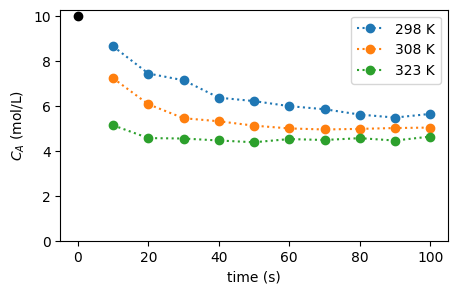

In [2]:
cA0 = 10.0   # mol/L
times = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100.])   # s
cA_data = {   # mol/L, keyed by temperature in K
    298.15: np.array([8.649, 7.441, 7.141, 6.366, 6.215, 5.990, 5.852, 5.615, 5.481, 5.644]),
    308.15: np.array([7.230, 6.073, 5.452, 5.317, 5.121, 4.998, 4.951, 4.978, 5.015, 5.036]),
    323.15: np.array([5.137, 4.568, 4.548, 4.461, 4.382, 4.525, 4.483, 4.565, 4.459, 4.635]),
}
temperatures = np.array(list(cA_data))

for T, cA in cA_data.items():
    plt.plot(times, cA, 'o:', label=f'{T:.0f} K')
plt.plot(0, cA0, 'ko')
plt.xlabel('time (s)')
plt.ylabel('$C_A$ (mol/L)')
plt.ylim(0, None)
plt.legend()
plt.show()

## 1. One temperature

**(a) The model.** Write `cA_model(times, kf, kr)`, which solves the ODE with
`scipy.integrate.solve_ivp` and returns $C_A$ at `times` (use `t_eval`). In Lecture 13 we fitted
functions that were a formula. `curve_fit` doesn't care: any function that takes the
independent variable first and then the parameters, and returns predictions, will do. Even
one that runs a whole simulation.

Then **test it** (Lecture 11). This ODE has an exact solution,
$$C_A(t) = C_{A,\mathrm{eq}} + (C_{A,0} - C_{A,\mathrm{eq}})\,e^{-(k_f+k_r)t},
\qquad C_{A,\mathrm{eq}} = C_{A,0}\frac{k_r}{k_f+k_r}$$
Check that your function agrees with it, for some reasonable $k_f$ and $k_r$, with an
`assert`. (We use `solve_ivp` anyway because your project's model won't have an exact
solution.)

In [3]:
def cA_model(times, kf, kr):
    """C_A (mol/L) at each of `times` (s), for rate constants kf and kr (1/s)."""
    times = np.asarray(times, dtype=float)
    if times.ndim != 1 or times.size == 0:
        raise ValueError("times must be a nonempty one-dimensional array")
    if np.any(times < 0) or np.any(np.diff(times) < 0):
        raise ValueError("times must be nonnegative and sorted")
    if times[-1] == 0:
        return np.full(times.shape, cA0, dtype=float)

    def rhs(t, y):
        cA = y[0]
        cB = cA0 - cA
        return [kr * cB - kf * cA]

    solution = scipy.integrate.solve_ivp(
        rhs,
        (0.0, float(times[-1])),
        [cA0],
        t_eval=times,
        rtol=1e-9,
        atol=1e-11,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    return solution.y[0]


# Check the ODE solver against the analytical solution.
test_kf, test_kr = 0.03, 0.02
test_times = np.array([0.0, 1.0, 10.0, 50.0])
test_ceq = cA0 * test_kr / (test_kf + test_kr)
test_exact = test_ceq + (cA0 - test_ceq) * np.exp(-(test_kf + test_kr) * test_times)
assert np.allclose(cA_model(test_times, test_kf, test_kr), test_exact, rtol=1e-7, atol=1e-9)
print("ODE model matches the exact solution for the test rates.")


ODE model matches the exact solution for the test rates.


**(b) Fit it at 298.15 K**, with `scipy.optimize.curve_fit`. **Try it without `p0` first.**
It may fail with an error from deep inside SciPy, or it may appear to succeed. Either way,
find out what happened: print and plot what came back, or what `cA_model` returns
at `curve_fit`'s default starting point. Then give it a starting guess you can justify
from the data. Roughly how long does $C_A$ take to get halfway to where it ends up?

In [4]:
# First try curve_fit's default starting values (both rates start at 1 s^-1).
# It may return a numerical result, so check whether that result actually fits the data.
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    try:
        default_fit = scipy.optimize.curve_fit(cA_model, times, cA_data[298.15])
        default_params = default_fit[0]
        default_residuals = cA_data[298.15] - cA_model(times, *default_params)
        print("Default-start parameters:", default_params, "s^-1")
        print(f"Default-start sum of squared residuals: {np.sum(default_residuals**2):.3f} (mol/L)^2")
    except RuntimeError as error:
        print("Default-start fit failed:", error)

# The data fall from 10 toward about 5.5 mol/L over roughly 100 s, so rates
# around 10^-2 s^-1 are a more realistic starting scale than 1 s^-1.
p0_298 = (0.02, 0.015)
params_298, pcov_298 = scipy.optimize.curve_fit(
    cA_model, times, cA_data[298.15], p0=p0_298, maxfev=10000
)
perr_298 = np.sqrt(np.diag(pcov_298))  # one-standard-error uncertainties
kf_298, kr_298 = params_298
half_time_298 = np.log(2) / (kf_298 + kr_298)
print(f"Initial guess (kf, kr): {p0_298} s^-1")
print(f"Fit (kf, kr): {kf_298:.6f}, {kr_298:.6f} s^-1")
print(f"One-SE uncertainties: {perr_298[0]:.6f}, {perr_298[1]:.6f} s^-1")
print(f"Model half-time toward equilibrium: {half_time_298:.1f} s")


Default-start parameters: [197.59409256 357.35294292] s^-1
Default-start sum of squared residuals: 9.211 (mol/L)^2
Initial guess (kf, kr): (0.02, 0.015) s^-1
Fit (kf, kr): 0.016799, 0.020064 s^-1
One-SE uncertainties: 0.000786, 0.001543 s^-1
Model half-time toward equilibrium: 18.8 s


**(c) Look at it.** Plot the data and the fitted curve, and below it the residuals
(data minus model). Report $k_f$ and $k_r$ with their uncertainties.

What happened without `p0`, and why? What starting guess did you use, and how did you
choose it?

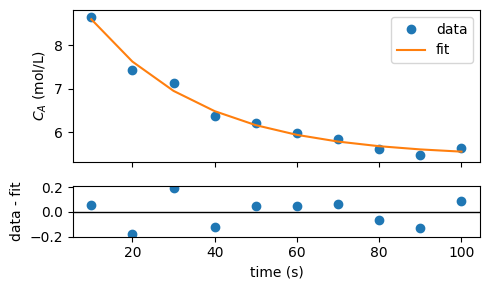

In [6]:
fit_298 = cA_model(times, *params_298)
residuals_298 = cA_data[298.15] - fit_298

fig, (ax, ax_res) = plt.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot(times, cA_data[298.15], "o", label="data")
ax.plot(times, fit_298, "-", label="fit")
ax.set_ylabel("$C_A$ (mol/L)")
ax.legend()
ax_res.axhline(0, color="black", linewidth=1)
ax_res.plot(times, residuals_298, "o")
ax_res.set_xlabel("time (s)")
ax_res.set_ylabel("data - fit")
fig.tight_layout()
plt.show()


*Answer:* With no `p0`, `curve_fit` does not immediately fail, but its default starting values are both 1 s$^{-1}$, much faster than the roughly 20 s decay suggested by the data. It returns extremely large rates ($k_fpprox198$ and $k_rpprox357$ s$^{-1}$), a poor fit. I therefore started at $k_f=0.02$ and $k_r=0.015$ s$^{-1}$, on the scale implied by the observed time course. The fit gives $k_f=0.01680\pm0.00079$ s$^{-1}$ and $k_r=0.02006\pm0.00154$ s$^{-1}$. Each $\pm$ is one standard error from the diagonal of the `curve_fit` covariance matrix. The fitted half-time, $\ln 2/(k_f+k_r)$, is about 18.8 s; visually the data reach about halfway toward their apparent endpoint within roughly 20 s.

## 2. Three temperatures, in two steps

**(a)** Fit $k_f$ and $k_r$ separately at each temperature, and make a small table of
$k_f$, $k_r$ (each with its ±) and $K = k_f/k_r$.

**Before fitting anything else:** from your $K$ values alone, is the reaction endothermic
or exothermic? How can you tell?

In [7]:
rate_fits = {}
print("T (K)   kf (s^-1)        kr (s^-1)        K = kf/kr")
for T in temperatures:
    params, covariance = scipy.optimize.curve_fit(
        cA_model, times, cA_data[T], p0=(0.02, 0.015), maxfev=10000
    )
    errors = np.sqrt(np.diag(covariance))  # one standard error
    kf, kr = params
    K = kf / kr
    # Delta-method uncertainty for the ratio, including the fitted covariance.
    var_K = K**2 * (
        covariance[0, 0] / kf**2
        + covariance[1, 1] / kr**2
        - 2 * covariance[0, 1] / (kf * kr)
    )
    K_error = np.sqrt(var_K)
    rate_fits[T] = (params, covariance, errors, K, K_error)
    print(f"{T:6.2f}  {kf:.6f} ± {errors[0]:.6f}  "
          f"{kr:.6f} ± {errors[1]:.6f}  {K:.4f} ± {K_error:.4f}")


T (K)   kf (s^-1)        kr (s^-1)        K = kf/kr
298.15  0.016799 ± 0.000786  0.020064 ± 0.001543  0.8373 ± 0.0306
308.15  0.039260 ± 0.000854  0.039249 ± 0.001060  1.0003 ± 0.0092
323.15  0.118945 ± 0.006415  0.097517 ± 0.005620  1.2197 ± 0.0123


**(b) Arrhenius.** As in Lecture 13: `scipy.stats.linregress` on $\ln k_f$ against
$1/T$ gives $E_a$ from the slope and $\ln A$ from the intercept. Convert $\ln A$ to
$\log_{10} A$.

**(c) van 't Hoff.** Put the two expressions for $\Delta G^\circ$ together and divide by $-RT$:
$$\ln K = -\frac{\Delta H}{R}\,\frac{1}{T} + \frac{\Delta S}{R}$$
So $\ln K$ against $1/T$ is a straight line too, with slope $-\Delta H/R$ and intercept
$\Delta S/R$. Fit it, and get $\Delta H$ and $\Delta S$, with their ±. Does the sign of
$\Delta H$ agree with what you said in (a)?

In [8]:
kf_by_T = np.array([rate_fits[T][0][0] for T in temperatures])
K_by_T = np.array([rate_fits[T][3] for T in temperatures])

arrhenius_fit = scipy.stats.linregress(1 / temperatures, np.log(kf_by_T))
Ea_2 = -arrhenius_fit.slope * R / 1000  # kJ/mol
Ea_2_se = arrhenius_fit.stderr * R / 1000
log10A_2 = arrhenius_fit.intercept / np.log(10)
log10A_2_se = arrhenius_fit.intercept_stderr / np.log(10)

vanthoff_fit = scipy.stats.linregress(1 / temperatures, np.log(K_by_T))
dH_2 = -vanthoff_fit.slope * R / 1000  # kJ/mol
dH_2_se = vanthoff_fit.stderr * R / 1000
dS_2 = vanthoff_fit.intercept * R  # J/mol/K
dS_2_se = vanthoff_fit.intercept_stderr * R

print(f"log10(A) = {log10A_2:.3f} ± {log10A_2_se:.3f}")
print(f"Ea = {Ea_2:.3f} ± {Ea_2_se:.3f} kJ/mol")
print(f"Delta H = {dH_2:.3f} ± {dH_2_se:.3f} kJ/mol")
print(f"Delta S = {dS_2:.3f} ± {dS_2_se:.3f} J/mol/K")
print("Each ± is one standard error from the regression output.")


log10(A) = 9.201 ± 0.172
Ea = 62.621 ± 1.021 kJ/mol
Delta H = 11.988 ± 0.736 kJ/mol
Delta S = 38.794 ± 2.379 J/mol/K
Each ± is one standard error from the regression output.


**(d)** `linregress` gave you a ± on each of these. What does that ± know about,
and what has it left out? Think about how many points each straight line had, and about
the ± you got in (a).

*Answer:* The fitted equilibrium constants increase with temperature ($Kpprox0.837$, $1.000$, and $1.220$ at 298, 308, and 323 K). Since products are increasingly favored as temperature rises, the reaction is endothermic; the van ’t Hoff fit agrees, giving $\Delta H=+11.99\pm0.74$ kJ/mol. All reported $\pm$ values are one standard error. The separate Arrhenius fit gives $\log_{10}A=9.201\pm0.172$ and $E_a=62.62\pm1.02$ kJ/mol; the van ’t Hoff fit gives $\Delta S=38.79\pm2.38$ J/mol/K.

`linregress` estimates uncertainty from the scatter about each straight line and treats the three temperatures (the $x$ values) as exact. It does not carry forward the uncertainty or covariance in each independently fitted $k_f$, $k_r$, or $K$. Each regression has only three points, so its residual-based error estimate has just one degree of freedom and is quite uncertain.

## 3. All the data at once

Step 2 fitted 3 × 2 rate constants, then fitted lines through three points each. Better:
fit the four parameters you actually want **directly to all 30 measurements**, so that
every measurement counts and the uncertainties carry all the way through.

`curve_fit` wants one `xdata` and one `ydata`. With several experiments, stack them:
`ydata` is all 30 concentrations in one array, and `xdata` carries **both** the
temperature and the time of each one. `curve_fit` never looks inside `xdata`; it just passes it
to your function. So it can be a tuple of two arrays:

In [9]:
T_all = np.repeat(temperatures, len(times))     # 298.15 ten times, then 308.15 ten times, ...
t_all = np.tile(times, len(temperatures))        # 10, 20, ..., 100, three times over
cA_all = np.concatenate([cA_data[T] for T in temperatures])
x_all = (T_all, t_all)
print(T_all[:12], t_all[:12], cA_all[:12], sep='\n')

[298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15
 308.15 308.15]
[ 10.  20.  30.  40.  50.  60.  70.  80.  90. 100.  10.  20.]
[8.649 7.441 7.141 6.366 6.215 5.99  5.852 5.615 5.481 5.644 7.23  6.073]


**(a)** Write `cA_model_all(x, log10A, Ea, dH, dS)`. Unpack `x` into temperatures and
times. For each temperature, work out $k_f$, $K$ and $k_r$, then call your `cA_model` for
that temperature's times, and put the results in the right places of the output array.
Solve one ODE per temperature, not one per data point. A boolean mask such as
`T_col == T` picks out the rows.

Notice the **units**: $E_a$ and $\Delta H$ in kJ/mol, $\Delta S$ in J/mol/K, and $A$ as
$\log_{10}A$. That keeps all four parameters between about 1 and 100. An optimizer
has an easier time when its parameters are all a similar size than when one is
$10^{9}$ and another is $10^{-2}$. So convert carefully inside the function.

Then fit it, **starting from your answers to task 2**, and report the four parameters with
their ±.

In [10]:
def cA_model_all(x, log10A, Ea, dH, dS):
    """C_A (mol/L) for every (T, t) pair in x. Ea and dH in kJ/mol, dS in J/mol/K."""
    T_col, t_col = x
    


**(b)** Now start from your estimates from before the experiments instead (6, 45, −10, −50).
Does it find the same answer? How far did the data move you from what you expected?

**(c)** Compare with task 2. Are the centres the same? Are the error bars? Which set of
error bars would you believe, and why?

**(d) The correlation matrix.** The off-diagonal elements of `pcov` say how the errors in
the parameters go together (Lecture 13). Turn the covariance into correlations:
`pcov / np.outer(perr, perr)`. Which pairs are strongly correlated? Why those pairs?
(Think about Lecture 13's ridge, and about the range of temperatures you measured over.)
If someone quotes only your four ± values, what are they missing?

*Answer:*

## 4. Look at the residuals

**Always look at the residuals** (Lecture 13). Plot the residuals of the task 3 fit against
time, one colour per temperature, with a line at zero.

- Do you see a pattern, or does it look like noise?
- Is the scatter about the same width at all three temperatures? Least squares assumed it is.
- Nobody told you the measurement uncertainty, so `curve_fit` (with
  `absolute_sigma=False`, the default) estimated it from the scatter of the residuals.
  Work out that estimate yourself:
  $s = \sqrt{\sum_i r_i^2 / (N - p)}$, with $N$ data points and $p$ parameters. What does
  it say about how precisely $C_A$ was measured?
- Suppose the experimentalist now tells you their instrument is good to ±0.01 mol/L.
  What would that tell you about your model, or about the experiment?

*Answer:*

## 5. Your project

One paragraph. Which parameters in your project's model will come from fitting data, and
where will the data come from: your own simulations, the literature, a research group? What
can you say about the errors in those data? Are they the same absolute size, the same
relative size, or known point by point? And are any of your parameters likely to be
correlated, the way $E_a$ and $A$ are here?

*Answer:*

## Stretch problems (optional)

**(a) Untangle the ridge.** Write $k_f$ in terms of its value at a reference temperature in
the middle of your data, say $T_\mathrm{ref} = 310$ K:
$$k_f(T) = k_\mathrm{ref}\exp\left[-\frac{E_a}{R}\left(\frac{1}{T} - \frac{1}{T_\mathrm{ref}}\right)\right]$$
It's the same model, written differently. Fit $\log_{10}k_\mathrm{ref}$, $E_a$, $\Delta H$
and $\Delta S$, and look at the correlation matrix again. What changed, and why? Can you do
the same for $\Delta H$ and $\Delta S$?

**(b) Draw the posterior.** At 298.15 K only, put $k_f$ and $k_r$ on a 2-D grid and draw
their posterior, as in Lecture 13, part 5, with a flat prior and Gaussian errors of width
$s$ from task 4. Do its 95% credible intervals (summed over the other parameter) agree with
`curve_fit`'s 95% confidence intervals? Why should they, or why not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors, and that the plots
are there. Commit and push. Then check on GitHub that your fork shows your latest commit.